In [2]:
import pertpy as pt
print(pt.__version__)

1.0.3


In [2]:
# from pertpy.tl import EdgeR

In [3]:
import warnings

import decoupler as dc
import scanpy as sc

warnings.filterwarnings("ignore")

## Dataset

In [4]:
#PATH = '/nfs/team298/ls34/adult_skin/final_adatas/adata_combined_new.h5ad.final.filtered'
PATH = '/nfs/team361/ls34/inflow/adata_hs_tdc.h5ad'

adata_5k=sc.read_h5ad(PATH)
#adata_5k=adata_5k[adata_5k.obs["tech"]=="xenium"].copy()
import gc
gc.collect()


def remove_markers(LIST):
    try: 
        LIST = {key: [gene for gene in genes if gene in adata_5k.var_names] 
                           for key, genes in LIST.items()}
    except: 
        LIST =[gene for gene in LIST if gene in adata_5k.var_names]
    return LIST



adata_5k.obs["lvl5_annotation_new"]=adata_5k.obs["fine_annotation"]

adata=adata_5k

adata.obs["sample_id"].value_counts()

sample_id
output-XETG00272__0041416__BK22-SKI-27-FO-1-S10-A1__20241107__113553    5045
output-XETG00155__0043607__BK39-SKI-27-FO-1-S3__20241010__133127        1962
output-XETG00272__0021042__AX29-SKI-0-FO-1-S4__20240815__114049         1412
output-XETG00155__0032945__AX34-SKI-0-FO-2-S3-A2__20241217__145711      1281
output-XETG00272__0027175__Region_7__20240628__124459                   1269
output-XETG00272__0041416__BK23-SKI-27-FO-1-S6-C2__20241107__113553     1003
output-XETG00155__0043607__BK30-SKI-27-FO-1-2-S3__20241010__133127       863
output-XETG00272__0027131__Region_7__20240628__124459                    757
output-XETG00272__0021042__AX30-SKI-0-FO-1-S3__20240815__114049          575
output-XETG00155__0032957__AX38-SKI-0-FO-1-S3-B1__20241217__145711       437
Name: count, dtype: int64

In [5]:
#adata = adata[adata.obs["Site_status_v"] == "Lesional", :].copy()
#adata.obs.Site_status_binary.value_counts()
adata.obs["Patient"]=adata.obs["sample_id"]
#adata.obs["Patient"]=adata.obs["sample_id"]
adata.obs["Sample"]=adata.obs["sample_id"]
# Step 1: Calculate total counts per patient
patient_counts = adata.obs.groupby("Patient").size()

# Step 2: Identify patients with more than 5000 counts
#patients_to_exclude = patient_counts[patient_counts < 10000].index

# Step a: Exclude those patients from adata
#adata = adata[~adata.obs["Patient"].isin(patients_to_exclude)].copy()
#adata=adata[adata.obs["Timepoint"]!="UNKNOWN_FFPE"]
#a#data.obs["Patient"].value_counts()
#adata=adata[~adata.obs["Patient"].isin(['BK50', 'BK49', 'BK43', 'BK46', 'BK51'])]
adata.obs["Group"]=adata.obs["Site_status_binary"]
adata.obs["disease_overall"]=adata.obs["disease"]

adata.obs["Major celltype"] = adata.obs["fine_annotation"]
adata.obs["Cluster"]=adata.obs["fine_annotation"] 

In [6]:
for x in adata.obs.columns:
    if x not in ["Cluster", "Major celltype", "disease_overall", "Site_status", "Group", "Sample", "Patient"]:
        del(adata.obs[x])


In [7]:
# {x:"" for x in adata[adata.obs["disease_overall"]=="Psoriasis"].obs["Sample"].unique()}

When conducting differential gene expression analysis, it is important to understand the dataset well.
We will therefore explore the various co-variates first.

In [8]:
# RENAME = {'output-XETG00155__0056910__CE6-SKI-28-FO-1-S22-B2__20250321__130447': 'CE6',
#  'output-XETG00155__0056910__CE5-SKI-28-FO-1-S22-A1__20250321__130447': 'CE5',
#  'output-XETG00155__0056918__CE3-SKI-28-FO-1-S22-B1__20250321__130447': 'CE3',
#  'output-XETG00155__0056918__CE4-SKI-27-FO-1-S22-B2__20250321__130447': 'CE4',
#  'output-XETG00155__0056910__CE6-SKI-28-FO-4-S22-A1__20250321__130447': 'CE6',
#  'output-XETG00155__0056910__CE5-SKI-27-FO-2-S22-C1__20250321__130447': 'CE5',
#  'output-XETG00155__0056918__CE3-SKI-24-FO-1-S22-A1__20250321__130447': 'CE3',
#  'output-XETG00155__0056918__CE4-SKI-21-FO-1-S22-C2__20250321__130447': 'CE4',
#  'output-XETG00155__0056910__CE5-SKI-27-FO-1-S22-B1__20250321__130447': 'CE5',
#  'output-XETG00155__0056918__CE3-SKI-28-FO-2-S22-C1__20250321__130447': 'CE3',
#  'output-XETG00155__0056918__CE4-SKI-27-FO-4-S22-A2__20250321__130447': 'CE4',
#  'output-XETG00155__0056910__CE6-SKI-20-FO-1-S22-C2__20250321__130447': 'CE6'}
# adata.obs["Patient"] = adata.obs["Sample"].map(RENAME).fillna(adata.obs["Patient"])

## Pseudobulks

In [9]:
adata.layers["counts"] = adata.X.copy()


In [10]:
# adata.X=adata.layers["counts"].copy()

In [11]:
# adata.obs["Drug"]=adata.obs["Group"]
# adata.obs["Drug"]=adata.obs["Drug"].astype(str)
# #adata.obs["Group"]=adata.obs["Group"].astype('category')
# adata.obs["Group2"]=adata.obs["Group"].astype(str)

# adata

In [12]:
# adata_i=adata[adata.obs["Site_status"]=="Lesional"]

In [13]:
adata_i=adata.copy()
# adata_i[(adata_i.obs["Cluster"].str.startswith("MigDC (cDC2"))
#               # (adata_i.obs["Cluster"].str.startswith("F1"))
#                ].copy()

In [14]:
# adata_i=adata_i.copy()

In [15]:
help(pt.tl.PseudobulkSpace.compute)


Help on function compute in module pertpy.tools._perturbation_space._simple:

compute(self, adata: 'AnnData', target_col: 'str' = 'perturbation', groups_col: 'str' = None, layer_key: 'str' = None, embedding_key: 'str' = None, mode: "Literal['count_nonzero', 'mean', 'sum', 'var', 'median']" = 'sum') -> 'AnnData'
    Determines pseudobulks of an AnnData object.
    
    Args:
        adata: Anndata object of size cells x genes
        target_col: .obs column that stores the label of the perturbation applied to each cell.
        groups_col: Optional .obs column that stores a grouping label to consider for pseudobulk computation.
            The summarized expression per perturbation (target_col) and group (groups_col) is computed.
        layer_key: If specified pseudobulk computation is done by using the specified layer. Otherwise, computation is done with .X
        embedding_key: `obsm` key of the AnnData embedding to use for computation. Defaults to the 'X' matrix otherwise.
        

In [16]:
ps = pt.tl.PseudobulkSpace()
pdata = ps.compute(
    adata_i, 
    target_col='disease_overall',
    #target_col="disease_overall",
   groups_col="Patient", 
    layer_key="counts", mode="sum", #min_cells=20, min_counts=1000
)
pdata.obs
is 

,disease_overall,Patient,Site_status,Sample,Group,Major celltype,Cluster
AD_output-XETG00155__0043607__BK30-SKI-27-FO-1-2-S3__20241010__133127,AD,output-XETG00155__0043607__BK30-SKI-27-FO-1-2-...,NaN,NaN,NaN,NaN,NaN
AD_output-XETG00155__0043607__BK39-SKI-27-FO-1-S3__20241010__133127,AD,output-XETG00155__0043607__BK39-SKI-27-FO-1-S3...,NaN,NaN,NaN,NaN,NaN
AD_output-XETG00272__0027131__Region_7__20240628__124459,AD,output-XETG00272__0027131__Region_7__20240628_...,NaN,NaN,NaN,NaN,NaN
AD_output-XETG00272__0027175__Region_7__20240628__124459,AD,output-XETG00272__0027175__Region_7__20240628_...,NaN,NaN,NaN,NaN,NaN
AD_output-XETG00272__0041416__BK22-SKI-27-FO-1-S10-A1__20241107__113553,AD,output-XETG00272__0041416__BK22-SKI-27-FO-1-S1...,NaN,NaN,NaN,NaN,NaN
AD_output-XETG00272__0041416__BK23-SKI-27-FO-1-S6-C2__20241107__113553,AD,output-XETG00272__0041416__BK23-SKI-27-FO-1-S6...,NaN,NaN,NaN,NaN,NaN
HS_output-XETG00155__0032945__AX34-SKI-0-FO-2-S3-A2__20241217__145711,HS,output-XETG00155__0032945__AX34-SKI-0-FO-2-S3-...,NaN,NaN,NaN,NaN,NaN
HS_output-XETG00155__0032957__AX38-SKI-0-FO-1-S3-B1__20241217__145711,HS,output-XETG00155__0032957__AX38-SKI-0-FO-1-S3-...,NaN,NaN,NaN,NaN,NaN
HS_output-XETG00272__0021042__AX29-SKI-0-FO-1-S4__20240815__114049,HS,output-XETG00272__0021042__AX29-SKI-0-FO-1-S4_...,NaN,NaN,NaN,NaN,NaN
HS_output-XETG00272__0021042__AX30-SKI-0-FO-1-S3__20240815__114049,HS,output-XETG00272__0021042__AX30-SKI-0-FO-1-S3_...,NaN,NaN,NaN,NaN,NaN


In [1]:
import numpy as np
# 2. Filter pseudobulk samples that had too few cells in the underlying data
cells_per_sample = (
    adata_i.obs
    .groupby(["disease_overall", "Patient"])
    .size()
)
keep_groups = cells_per_sample[cells_per_sample >= 20].index

# pdata.obs holds the (disease, patient) identity for each pseudobulk row
sample_keys = pdata.obs[["disease_overall", "Patient"]].apply(tuple, axis=1)
keep_mask = sample_keys.isin(keep_groups).values

# 3. Filter pseudobulk samples with too few total counts
total_counts = np.asarray(pdata.X.sum(axis=1)).ravel()
keep_mask &= (total_counts >= 1000)

pdata = pdata[keep_mask].copy()
print(f"kept {pdata.n_obs} pseudobulk samples after filtering")
print("samples per disease:")
print(pdata.obs["disease_overall"].value_counts())
print(f"unique patients: {pdata.obs['Patient'].nunique()}")



NameError: name 'adata_i' is not defined

In [ ]:
pdata.layers["counts"] = pdata.X.copy()
#pdata.X=pdata.layers["counts"].copy()

sc.pp.normalize_total(pdata, target_sum=1e4)
sc.pp.log1p(pdata)
sc.pp.scale(pdata, max_value=10)
sc.tl.pca(pdata)

# Return raw counts to X
dc.swap_layer(pdata, "counts", X_layer_key=None, inplace=True)


In [19]:
# sc.pl.pca(pdata, color=["disease_overall"], ncols=1, size=300) # "Efficacy", 
# sc.pl.pca(pdata, color=["Cluster"], ncols=1, size=300, legend_loc="on data") # "Efficacy", 
# sc.pl.pca(pdata, color=["Cluster"], ncols=1, size=300, #legend_loc="on data"
#          ) # "Efficacy", 


In [20]:
# sc.pl.pca_variance_ratio(pdata)


In [21]:
# try:
#     dc.get_metadata_associations(
#         pdata,
#         obs_keys=[ "disease_overall", "Patient", "psbulk_n_cells", "psbulk_counts"], # "Treatment", "Patient",
#         obsm_key="X_pca",
#         uns_key="pca_anova",
#         inplace=True,
#     )
#     pdata
# except:
#     1

In [22]:
# try:
#     dc.plot_associations(
#         pdata,
#         uns_key="pca_anova",
#         obsm_key="X_pca",
#         stat_col="p_adj",
#         obs_annotation_cols=["disease_overall",  #"Treatment", "Efficacy", 
#                              "Major celltype"],
#         titles=["Principle component scores", "Adjusted p-values from ANOVA"],
#     )
# except:
#     1

In [23]:
edgr = pt.tl.PyDESeq2(adata=pdata, design="~disease_overall")


In [24]:
edgr.fit()


Using None as control genes, passed at DeseqDataSet initialization


Fitting size factors...
... done in 0.00 seconds.

Fitting dispersions...
... done in 0.35 seconds.

Fitting dispersion trend curve...
... done in 0.28 seconds.

Fitting MAP dispersions...
... done in 0.45 seconds.

Fitting LFCs...
... done in 0.32 seconds.

Calculating cook's distance...
... done in 0.01 seconds.

Replacing 0 outlier genes.



In [25]:
pdata.obs.disease_overall

AD_output-XETG00155__0043607__BK30-SKI-27-FO-1-2-S3__20241010__133127      AD
AD_output-XETG00155__0043607__BK39-SKI-27-FO-1-S3__20241010__133127        AD
AD_output-XETG00272__0027131__Region_7__20240628__124459                   AD
AD_output-XETG00272__0027175__Region_7__20240628__124459                   AD
AD_output-XETG00272__0041416__BK22-SKI-27-FO-1-S10-A1__20241107__113553    AD
AD_output-XETG00272__0041416__BK23-SKI-27-FO-1-S6-C2__20241107__113553     AD
HS_output-XETG00155__0032945__AX34-SKI-0-FO-2-S3-A2__20241217__145711      HS
HS_output-XETG00155__0032957__AX38-SKI-0-FO-1-S3-B1__20241217__145711      HS
HS_output-XETG00272__0021042__AX29-SKI-0-FO-1-S4__20240815__114049         HS
HS_output-XETG00272__0021042__AX30-SKI-0-FO-1-S3__20240815__114049         HS
Name: disease_overall, dtype: category
Categories (2, object): ['AD', 'HS']

In [26]:
res_df = edgr.test_contrasts(edgr.contrast(column="disease_overall", baseline="HS", group_to_compare="AD"))


Running Wald tests...


Log2 fold change & Wald test p-value, contrast vector: [ 0. -1.]
          baseMean  log2FoldChange     lfcSE      stat    pvalue      padj
ABAT     19.318880       -0.150423  0.418679 -0.359281  0.719385  0.867296
ABCA4     1.882340        0.368692  1.936766  0.190365  0.849023  0.936341
ABCB4     3.543308       -0.035988  0.759862 -0.047361  0.962225  0.985694
ABCC4    17.633920        0.223116  0.486588  0.458531  0.646571  0.819803
ABCC8     0.445553       -1.411386  2.572572 -0.548628  0.583260       NaN
...            ...             ...       ...       ...       ...       ...
ZNF177    1.061686       -0.272934  1.423643 -0.191715  0.847965  0.936341
ZNF469   36.922310       -1.472911  0.502301 -2.932331  0.003364  0.023846
ZNF512   95.253863        0.080693  0.295992  0.272618  0.785147  0.900373
ZNF683  441.526445       -0.869884  0.561370 -1.549575  0.121244  0.316615
ZSWIM6    5.871845        0.052547  0.588620  0.089271  0.928866  0.966708

[1213 rows x 6 columns]


... done in 88.57 seconds.



In [27]:
# res_df.head(10)

The set of differentially expressed genes can now be used for downstream tasks or as a first step, plotted in a volcano plot.

NaNs encountered, dropping rows with NaNs


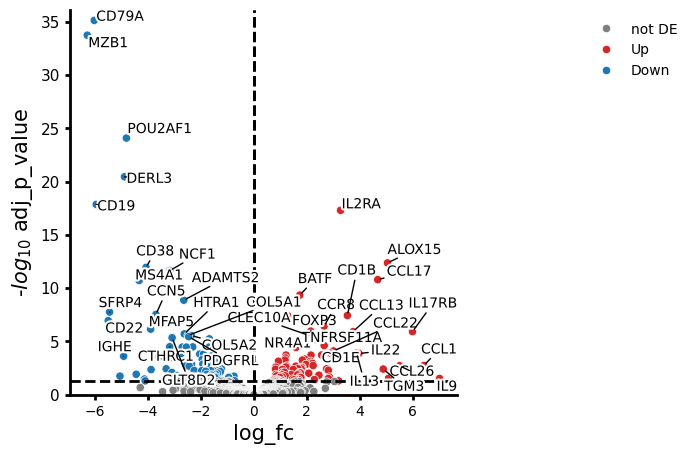

In [28]:
edgr.plot_volcano(res_df, 
                  log2fc_thresh=0,
                     to_label=20
                  ,
                     #    log2fc_thresh=0.
                 )

In [30]:
res_df

,variable,baseMean,log_fc,lfcSE,stat,p_value,adj_p_value,contrast
0,CD79A,128.279908,-6.037879,0.463042,-13.039586,7.285175e-39,7.343456e-36,None
1,MZB1,274.600819,-6.302534,0.494736,-12.739189,3.580996e-37,1.804822e-34,None
2,POU2AF1,78.493445,-4.823599,0.445313,-10.831941,2.429488e-27,8.163079e-25,None
3,DERL3,113.996828,-4.895260,0.489118,-10.008348,1.400717e-23,3.529806e-21,None
4,CD19,43.518280,-5.963011,0.635875,-9.377641,6.746532e-21,1.360101e-18,None
...,...,...,...,...,...,...,...,...
1208,SHOX,0.000000,NaN,NaN,NaN,NaN,NaN,None
1209,SLC25A31,0.000000,NaN,NaN,NaN,NaN,NaN,None
1210,SPINK7,0.000000,NaN,NaN,NaN,NaN,NaN,None
1211,SPTA1,0.000000,NaN,NaN,NaN,NaN,NaN,None


In [31]:
import pandas as pd

# Set genes as index for easy lookup
res_df = res_df.set_index("variable")

# Drop genes with NaN results (baseMean == 0; not testable)
res_df = res_df.dropna(subset=["adj_p_value", "log_fc"])

PADJ_THRESH = 0.05
LFC_THRESH  = 1.0

# Confirm contrast direction: baseline="HS", group_to_compare="AD"
# → positive log_fc = up in AD; negative = up in HS
# BUT verify by checking a known marker (see below)

# AD-preferential: significantly higher in AD vs HS
ad_preferential = res_df[
    (res_df["adj_p_value"] < PADJ_THRESH) & (res_df["log_fc"] >  LFC_THRESH)
]
# HS-preferential: significantly higher in HS vs AD
hs_preferential = res_df[
    (res_df["adj_p_value"] < PADJ_THRESH) & (res_df["log_fc"] < -LFC_THRESH)
]
# Not significantly differential (or small effect)
shared = res_df[
    (res_df["adj_p_value"] >= PADJ_THRESH) | (res_df["log_fc"].abs() <= LFC_THRESH)
]

X = len(ad_preferential)
Y = len(hs_preferential)
Z = len(shared)
print(f"X (AD-preferential):   {X}")
print(f"Y (HS-preferential):   {Y}")
print(f"Z (not differential):  {Z}")

print("\nTop 15 AD-preferential genes:")
print(ad_preferential.sort_values("log_fc", ascending=False).head(15)[["log_fc", "adj_p_value"]])

print("\nTop 15 HS-preferential genes:")
print(hs_preferential.sort_values("log_fc").head(15)[["log_fc", "adj_p_value"]])

X (AD-preferential):   69
Y (HS-preferential):   87
Z (not differential):  852

Top 15 AD-preferential genes:
            log_fc   adj_p_value
variable                        
IL9       7.016038  3.002441e-02
CCL1      6.425082  1.811055e-03
IL17RB    5.994987  1.178906e-06
CCL26     5.501255  1.898498e-03
H19       5.086748  2.924565e-02
ALOX15    5.047918  4.285330e-13
TGM3      4.887855  3.884893e-03
CCL17     4.679278  1.580104e-11
IL22      3.967790  1.362787e-04
IL13      3.880181  1.266663e-04
CCL13     3.743364  1.211739e-06
CD1B      3.531334  3.673072e-08
IL2RA     3.274587  4.951477e-18
SERPINB2  3.200796  4.997861e-02
CCL22     3.006809  7.830866e-05

Top 15 HS-preferential genes:
            log_fc   adj_p_value
variable                        
MZB1     -6.302534  1.804822e-34
CD79A    -6.037879  7.343456e-36
CD19     -5.963011  1.360101e-18
CD22     -5.510348  1.104372e-07
SFRP4    -5.458944  1.756264e-08
COL11A1  -5.065463  1.793248e-02
IGHE     -4.926313  2.436069e-04
D

In [ ]:
0

In [ ]:
0

In [ ]:
9

In [ ]:
0

In [ ]:
res_df

In [ ]:
# Build list of genes to label: starts with CCL, CXCL, or IL AND p_value < 0.05
genes_to_label = [
    g
    for g, p in zip(res_df["variable"], res_df["p_value"])
    if g.startswith(("CCL", "CXCL", "IL")) and p < 0.05
]

# Plot volcano
edgr.plot_volcano(
    res_df,
    log2fc_thresh=0,
    to_label=genes_to_label
)

In [ ]:
# Filter gene names that start with CCL or CXCL

# Plot volcano
edgr.plot_volcano(
    res_df,
    log2fc_thresh=0.5,      # keep as you had it
    to_label=genes_to_label
)

In [ ]:
fig = edgr.plot_volcano(
    res_df,
    log2fc_thresh=0,
    to_label=15,
    return_fig=True
)

fig.savefig("figures/degs_TDC.pdf", dpi=300, bbox_inches="tight")

In [ ]:
# import matplotlib.pyplot as plt

# edgr.plot_volcano(
#     res_df,
#     log2fc_thresh=0,
#     to_label=15
# )

# fig = plt.gcf()

# fig.savefig(
#     "figures/DEGS_TDC.pdf",
#     dpi=300,
#     bbox_inches="tight"
# )

In [ ]:
S

In [ ]:
fig = edgr.plot_volcano(
    res_df,
    log2fc_thresh=0,
    to_label=10,
    return_fig=True
)



In [ ]:
fig = edgr.plot_volcano(
    res_df,
    log2fc_thresh=0,
    to_label=5,
    return_fig=True
)

#fig.savefig("fig3/supp3g_migdc_Dec_cleaner.pdf", dpi=300, bbox_inches="tight")

In [ ]:
fig = edgr.plot_volcano(
    res_df,
    log2fc_thresh=0,
    to_label=1,
    return_fig=True
)

#fig.savefig("fig3/supp3g_migdc_Dec_cleanest.pdf", dpi=300, bbox_inches="tight")

In [ ]:
edgr.plot_fold_change(res_df, n_top_vars=30)


In [ ]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(6,6))

edgr.plot_volcano(
    res_df,
    log2fc_thresh=0,
    to_label=15,
    ax=ax
)

fig.savefig(
    "figures/DEGS_TDC.pdf",
    dpi=300,
    bbox_inches="tight"
)